# Додаткове завдання Adv 1. Кешування лічильника в Hazelcast: read-through, write-through і write-behind

Дисципліна «Проєктування високонавантажених систем», викладач Родіонов А. М.

Виконав: Вовкотруб Олександр Віталійович, група ФБ-61мн.
КПІ ім. Ігоря Сікорського, ННФТІ, кафедра інформаційної безпеки.

Ноутбук є аналітичною частиною звіту. Він читає результати прогонів
`reports/data/taskadv1.csv`, перевірки «мапа = таблиця»
`reports/data/taskadv1-check.csv`, вибірки значень під час прогону
`reports/data/taskadv1x-lag/*.csv` і протокол терміналу
`reports/logs/taskadv1-demo.txt`, рахує таблиці звіту і будує рисунки.
Наприкінці є жива перевірка на справжніх PostgreSQL і кластері.

## 0. Підготовка середовища

Корінь репозиторію шукаємо від поточної теки вгору до `Package.swift`.
Прапорець `RUN_LIVE` вмикає живу перевірку; вимкнути її можна змінною
оточення `HLS_NB_LIVE=0`.

In [1]:
import os
import re
import socket
import subprocess
import time
from pathlib import Path

import matplotlib

matplotlib.use("Agg")
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display


def find_root(start: Path) -> Path:
    for path in (start, *start.parents):
        if (path / "Package.swift").is_file():
            return path
    raise FileNotFoundError("Package.swift не знайдено вище від " + str(start))


ROOT = find_root(Path.cwd().resolve())
LAB = Path.cwd() if (Path.cwd() / "solution.ipynb").is_file() else next(
    p for p in (ROOT / "adv1", ROOT / "Labs" / "06-caching") if p.is_dir())
DATA = ROOT / "reports" / "data"
LOGS = ROOT / "reports" / "logs"
ASSETS = LAB / "assets"
ASSETS.mkdir(exist_ok=True)

RUN_LIVE = os.environ.get("HLS_NB_LIVE", "1") != "0"

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Liberation Sans", "DejaVu Sans"],
    "font.size": 14,
    "axes.titlesize": 14,
    "axes.labelsize": 14,
    "xtick.labelsize": 13,
    "ytick.labelsize": 14,
    "legend.fontsize": 12,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "figure.dpi": 100,
})
pd.set_option("display.width", 160)

# Ті самі кольори, що й у ноутбуках робіт № 1...5.
INK, GRID = "#1A233B", "#D7DAE3"
SCENARIO = {
    "postgres-users": "PostgreSQL",
    "hazelcast-write-through": "Hazelcast Write-through",
    "hazelcast-write-behind": "Hazelcast Write-behind",
}
COLOR = {
    "PostgreSQL": "#0E6BA8",
    "Hazelcast Write-through": "#B5432F",
    "Hazelcast Write-behind": "#1B8A5E",
}
EXPECTED = 100_000


def uk(x: float, digits: int = 0) -> str:
    """Число в українському записі: 4 447,0 (нерозривний пробіл, кома)."""
    return f"{x:,.{digits}f}".replace(",", " ").replace(".", ",")


def save(fig, name: str) -> None:
    """Зберегти рисунок у assets/ (dpi 200) і показати його в ноутбуці."""
    path = ASSETS / name
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(filename=str(path), width=820))
    print("збережено:", path.relative_to(ROOT))


def excerpt(rel: str, start: str, end: str | None = None, *, lines: int | None = None) -> None:
    """Надрукувати точний уривок файла з номерами рядків."""
    text = (ROOT / rel).read_text(encoding="utf-8").splitlines()
    first = next(i for i, line in enumerate(text) if start in line)
    if end is not None:
        last = next(i for i in range(first + 1, len(text)) if end in text[i])
    else:
        last = first + (lines or 1) - 1
    print(f"{rel}, рядки {first + 1}...{last + 1}")
    for i in range(first, last + 1):
        print(f"{i + 1:4d} | {text[i]}")


print("корінь репозиторію:", ROOT.name)
print("RUN_LIVE =", RUN_LIVE)

корінь репозиторію: HighLoadSystems
RUN_LIVE = True


## 1. Постановка

Лічильник кожного користувача зберігається в таблиці PostgreSQL
`user_likes (user_id bigint PRIMARY KEY, likes bigint)`. Веб-сервер з
роботи № 1 приймає `POST /inc?user_id=N` і збільшує лічильник одним із
трьох способів:

* `postgres-users`: напряму в таблицю, один upsert на інкремент;
* `hazelcast-write-through`: через `IMap` `likes_write_through` з
  оптимістичним блокуванням (`get`, потім `replace(key, old, old + 1)`),
  generic MapStore пише кожну зміну в таблицю до відповіді;
* `hazelcast-write-behind`: те саме через `IMap` `likes_write_behind`,
  зміни пишуться в таблицю через 5 с, лише останнє значення ключа.

Обидві мапи читають відсутній ключ з таблиці (read-through). Конфігурація
обох мап у файлі вузла:

In [2]:
yaml_lines = (ROOT / "deploy/hazelcast-node1.yaml").read_text(encoding="utf-8").splitlines()
excerpt("deploy/hazelcast-node1.yaml", "  jet:", lines=len(yaml_lines) - next(
    i for i, l in enumerate(yaml_lines) if l.startswith("  jet:")))

deploy/hazelcast-node1.yaml, рядки 39...78
  39 |   jet:
  40 |     enabled: true
  41 |   data-connection:
  42 |     likes-db:
  43 |       type: JDBC
  44 |       shared: true
  45 |       properties:
  46 |         jdbcUrl: jdbc:postgresql://127.0.0.1:21410/postgres
  47 |         user: postgres
  48 |   map:
  49 |     # Write-through: a change is in the table before the member answers.
  50 |     likes_write_through:
  51 |       map-store:
  52 |         enabled: true
  53 |         class-name: com.hazelcast.mapstore.GenericMapStore
  54 |         write-delay-seconds: 0
  55 |         properties:
  56 |           data-connection-ref: likes-db
  57 |           external-name: user_likes
  58 |           id-column: user_id
  59 |           columns: likes
  60 |           # The value is the likes column itself (a Long), not a GenericRecord.
  61 |           single-column-as-value: "true"
  62 |           # Read-through only: no loading of every row when the map starts.
  63 |       

Цикл оптимістичного інкременту в сервері:

In [3]:
excerpt("Sources/CounterCore/HazelcastCacheCounterStore.swift", "public func increment(user: Int64)", lines=20)

Sources/CounterCore/HazelcastCacheCounterStore.swift, рядки 50...69
  50 |     public func increment(user: Int64) async throws {
  51 |         var attempts = 0
  52 |         while true {
  53 |             guard let current = try await map.get(user, threadID: Self.threadID) else {
  54 |                 if try await map.putIfAbsent(user, 1, threadID: Self.threadID) == nil { break }
  55 |                 attempts += 1
  56 |                 conflicts.add(1, ordering: .relaxed)
  57 |                 continue
  58 |             }
  59 |             if try await map.replace(user, expected: current, new: current + 1, threadID: Self.threadID) { break }
  60 |             attempts += 1
  61 |             conflicts.add(1, ordering: .relaxed)
  62 |         }
  63 |         increments.add(1, ordering: .relaxed)
  64 |         if attempts > 0 {
  65 |             longestRetries.raise(to: attempts)
  66 |         }
  67 |     }
  68 | 
  69 |     public func value(user: Int64) async throws ->

## 2. Протокол терміналу

`scripts/taskadv1-demo.sh` (рисунки 3.1 і далі у звіті): таблиця і
налаштування, по три інкременти через кожну мапу з читанням таблиці
одразу після них, read-through після `evictAll`. Код перевіряє, що
протокол показує саме це.

In [4]:
demo = (LOGS / "taskadv1-demo.txt").read_text(encoding="utf-8")
print(demo)

# 1. Таблиця user_likes і налаштування MapStore обох мап (лише конфігурація, без власного коду).
[08:47:48.685] $ scripts/pg.sh psql -c \d user_likes
             Table "public.user_likes"
 Column  |  Type  | Collation | Nullable | Default 
---------+--------+-----------+----------+---------
 user_id | bigint |           | not null | 
 likes   | bigint |           | not null | 
Indexes:
    "user_likes_pkey" PRIMARY KEY, btree (user_id)

[08:47:48.722] $ grep -A 14 likes_write_through: deploy/hazelcast-node1.yaml
    likes_write_through:
      map-store:
        enabled: true
        class-name: com.hazelcast.mapstore.GenericMapStore
        write-delay-seconds: 0
        properties:
          data-connection-ref: likes-db
          external-name: user_likes
          id-column: user_id
          columns: likes
          # The value is the likes column itself (a Long), not a GenericRecord.
          single-column-as-value: "true"
          # Read-through only: no loading of every row w

In [5]:
def section(text: str, number: int) -> str:
    """Блок протоколу від примітки `# N.` до наступної."""
    return re.split(r"^# \d\. ", text, flags=re.M)[number]


def likes_after(block: str) -> list[int]:
    """Значення likes у кожній відповіді psql на SELECT у блоці."""
    return [int(m) for m in re.findall(r"^\s+42 \|\s+(\d+)$", block, re.M)]


wt_block, wb_block, rt_block = section(demo, 2), section(demo, 3), section(demo, 4)
print("write-through, таблиця після трьох інкрементів:", likes_after(wt_block))
print("write-behind, таблиця одразу і через 6 с:", likes_after(wb_block))
assert likes_after(wt_block) == [3]
wb_now, wb_later = likes_after(wb_block)
assert wb_now == 3 and wb_later == 6, "write-behind: таблиця має відставати, потім наздогнати"
reloaded = rt_block.strip().splitlines()
print("read-through:", [l for l in reloaded if "likes_write_behind" in l])
assert any(re.search(r"likes_write_behind,42,6,\d+,6,[\d.]+,true,6$", l) for l in reloaded)

write-through, таблиця після трьох інкрементів: [3]
write-behind, таблиця одразу і через 6 с: [3, 6]
read-through: ['[08:47:55.180] $ .build/release/cache-check --header --map likes_write_behind --users 42 --evict', ',likes_write_behind,42,6,6,6,0.00,true,6']


## 3. Таблиця завдання: 100 000 інкрементів одного користувача

10 клієнтів по 10 000 `POST /inc?user_id=1`. Медіана повторів, мінімум і
максимум; конфлікти: скільки разів `replace` не застосовано, бо значення
встигли змінити; рядків записано: вставлено й оновлено в `user_likes` за
прогін (`pg_stat_user_tables`, разом з одним `reset`).

In [6]:
runs = pd.read_csv(DATA / "taskadv1.csv")
runs["сценарій"] = runs["store"].map(SCENARIO)
assert (runs["final_value"] == EXPECTED).all() and runs["correct"].all()


def summary(users: str) -> pd.DataFrame:
    g = runs[runs["users"] == users].groupby("сценарій", sort=False)
    out = pd.DataFrame({
        "повторів": g.size(),
        "час, с (медіана)": g["seconds"].median(),
        "час, с (мін...макс)": g["seconds"].agg(lambda s: f"{uk(s.min(), 1)}...{uk(s.max(), 1)}"),
        "інкр./с (медіана)": g["rps"].median(),
        "фінальні значення": g["final_value"].agg(list),
        "конфліктів на інкремент": (g["conflicts"].median() / EXPECTED).round(2),
        "рядків записано (медіана)": g["db_rows_written"].median().astype(int),
    })
    return out.loc[[s for s in SCENARIO.values() if s in out.index]]


shared = summary("shared")
display(shared)

,повторів,"час, с (медіана)","час, с (мін...макс)",інкр./с (медіана),фінальні значення,конфліктів на інкремент,рядків записано (медіана)
сценарій,,,,,,,
PostgreSQL,3,149.9267,"148,7...150,3",667.0,"[100000, 100000, 100000]",NaN,100001
Hazelcast Write-through,3,323.2365,"322,6...421,7",309.4,"[100000, 100000, 100000]",4.60,100001
Hazelcast Write-behind,3,39.3664,"39,1...39,5",2540.2,"[100000, 100000, 100000]",4.48,39


In [7]:
task_table = pd.DataFrame({
    "Test scenarios": shared.index,
    "Total time": [f"{uk(t, 1)} с" for t in shared["час, с (медіана)"]],
    "Throughput": [f"{uk(r, 1)} інкр./с" for r in shared["інкр./с (медіана)"]],
})
display(task_table)
pg_s, wt_s, wb_s = (shared.loc[s, "інкр./с (медіана)"] for s in SCENARIO.values())
print(f"write-behind / PostgreSQL: {wb_s / pg_s:.2f}; PostgreSQL / write-through: {pg_s / wt_s:.1f}")

,Test scenarios,Total time,Throughput
0,PostgreSQL,"149,9 с","667,0 інкр./с"
1,Hazelcast Write-through,"323,2 с","309,4 інкр./с"
2,Hazelcast Write-behind,"39,4 с","2 540,2 інкр./с"


write-behind / PostgreSQL: 3.81; PostgreSQL / write-through: 2.2


## 4. Десять користувачів

Той самий прогін, але клієнт i збільшує лічильник користувача 1 + i: ключі
лежать у різних партиціях, і запити не конкурують за один ключ.

In [8]:
distinct = summary("distinct")
display(distinct)
pg_d, wt_d, wb_d = (distinct.loc[s, "інкр./с (медіана)"] for s in SCENARIO.values())
print(f"10 користувачів / 1: PostgreSQL {pg_d / pg_s:.1f}, write-through {wt_d / wt_s:.0f}, "
      f"write-behind {wb_d / wb_s:.1f}")
assert (runs.loc[runs["store"] == "hazelcast-write-through", "db_rows_written"] >= EXPECTED).all()
assert (runs.loc[runs["store"] == "hazelcast-write-behind", "db_rows_written"] < EXPECTED / 50).all()
assert (runs.loc[runs["users"] == "distinct", "conflicts"].fillna(0) == 0).all()

,повторів,"час, с (медіана)","час, с (мін...макс)",інкр./с (медіана),фінальні значення,конфліктів на інкремент,рядків записано (медіана)
сценарій,,,,,,,
PostgreSQL,3,28.8622,"28,9...29,1",3464.7,"[100000, 100000, 100000]",NaN,100010
Hazelcast Write-through,3,86.9936,"83,5...93,7",1149.5,"[100000, 100000, 100000]",0.0,100010
Hazelcast Write-behind,3,13.6540,"12,6...14,0",7323.8,"[100000, 100000, 100000]",0.0,126


10 користувачів / 1: PostgreSQL 5.2, write-through 4, write-behind 2.9


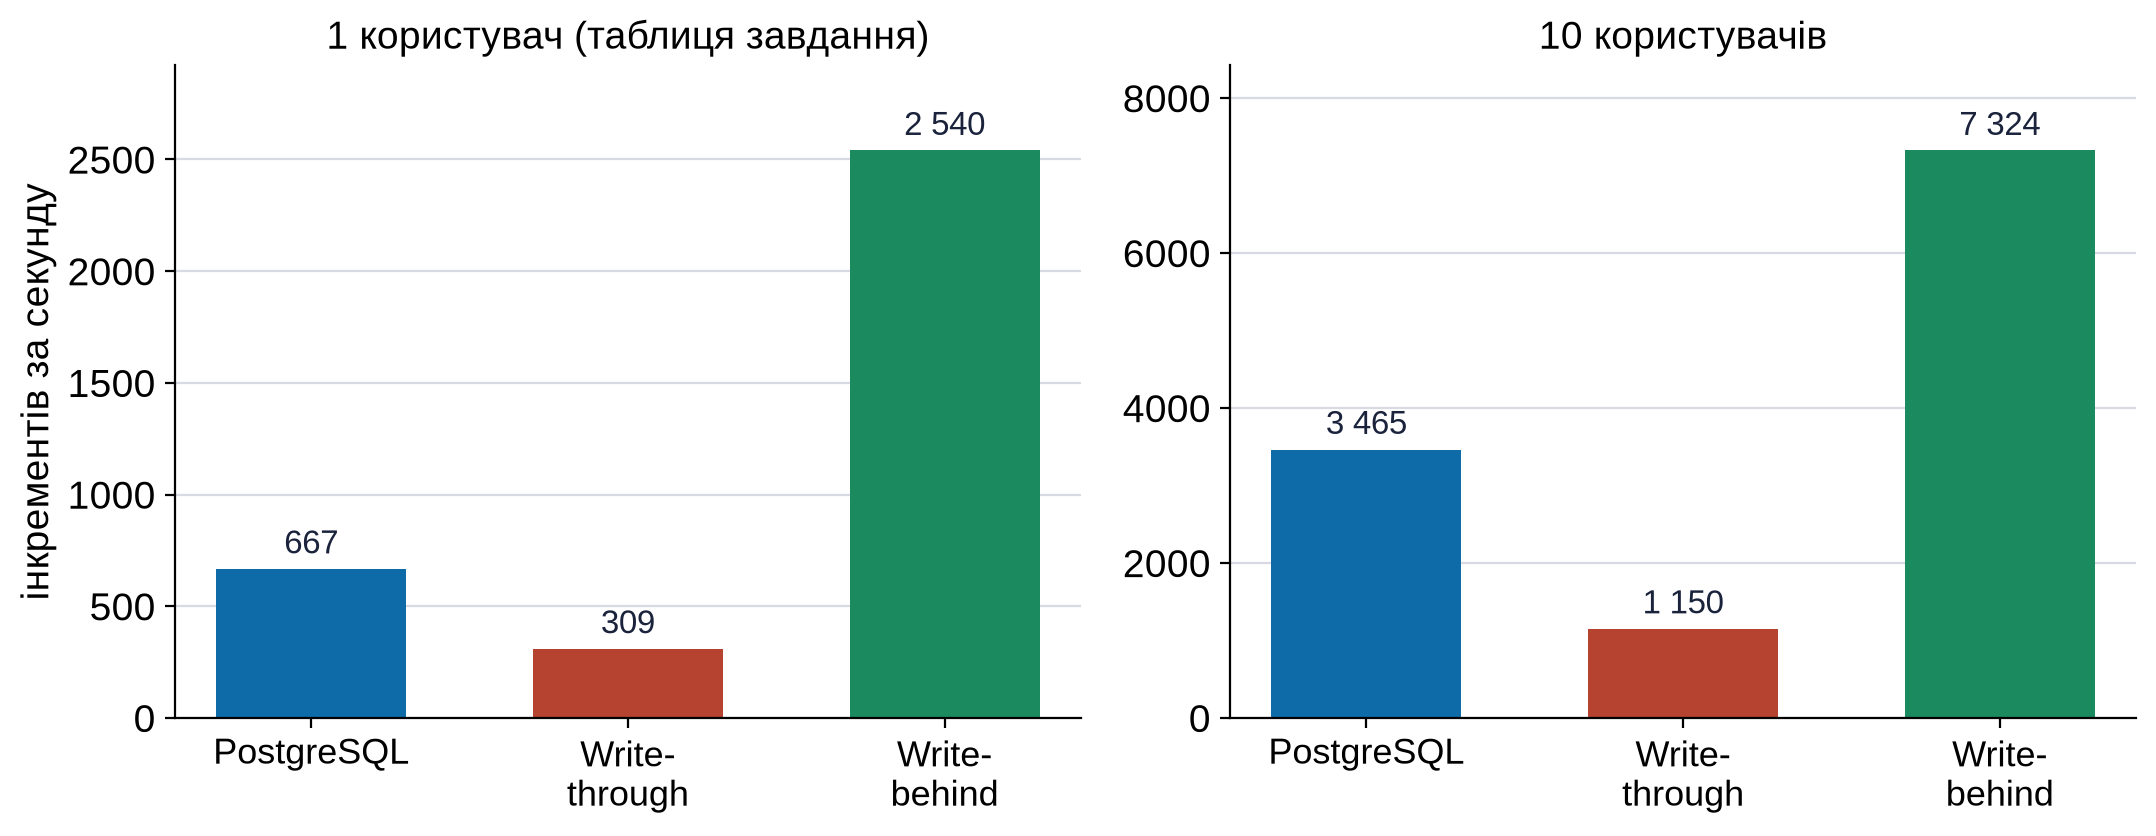

збережено: Labs/06-caching/assets/throughput.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, (title, table) in zip(axes, (("1 користувач (таблиця завдання)", shared),
                                     ("10 користувачів", distinct))):
    vals = table["інкр./с (медіана)"]
    bars = ax.bar(range(len(vals)), vals, color=[COLOR[s] for s in vals.index], width=0.6)
    ax.set_xticks(range(len(vals)), ["PostgreSQL", "Write-\nthrough", "Write-\nbehind"])
    ax.set_title(title)
    ax.grid(axis="y", color=GRID, linewidth=0.8)
    ax.set_ylim(0, vals.max() * 1.15)
    ax.set_axisbelow(True)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, v + vals.max() * 0.015, uk(v, 0), ha="center", va="bottom", fontsize=12, color=INK)
axes[0].set_ylabel("інкрементів за секунду")
fig.tight_layout()
save(fig, "throughput.png")

## 5. Значення в базі дорівнює значенню в `IMap`

`cache-check` після кожного прогону: значення в мапі, у таблиці одразу,
у таблиці після очікування (до 30 с) і в мапі після `evictAll`, тобто
прочитане з таблиці через MapLoader.

In [10]:
checks = pd.read_csv(DATA / "taskadv1-check.csv")
checks["users"] = checks["label"].str.split("-").str[1]
checks["сценарій"] = checks["map"].map({"likes_write_through": "Hazelcast Write-through",
                                        "likes_write_behind": "Hazelcast Write-behind"})
checks["відставала на"] = checks["imap"] - checks["db_at_start"]
g = checks.groupby(["users", "сценарій"], sort=False)
check_table = pd.DataFrame({
    "перевірок": g.size(),
    "мапа = таблиця": g["equal"].all(),
    "таблиця відставала одразу, інкр. (макс)": g["відставала на"].max(),
    "чекали, с (макс)": g["waited_seconds"].max(),
    "після evictAll = мапа": g.apply(lambda d: bool((d["reloaded_after_evict"] == d["imap"]).all())),
})
display(check_table)
assert checks["equal"].all() and (checks["reloaded_after_evict"] == checks["imap"]).all()
wt_checks = checks[checks["map"] == "likes_write_through"]
assert (wt_checks["db_at_start"] == wt_checks["imap"]).all(), "write-through: таблиця не відстає"
sums = checks.groupby("label")["imap"].sum()
assert (sums == EXPECTED).all()

перевірок  мапа = таблиця  таблиця відставала одразу, інкр. (макс)  чекали, с (макс)  після evictAll = мапа
users    сценарій                                                                                                                            
distinct Hazelcast Write-through         30            True                                        0              0.00                   True
         Hazelcast Write-behind          30            True                                      897              0.82                   True
shared   Hazelcast Write-behind           3            True                                     1011              0.96                   True
         Hazelcast Write-through          3            True                                        0              0.00                   True

## 6. Додаткове дослідження: як таблиця відстає від мапи

`scripts/taskadv1x-lag.sh`: під час прогону `cache-check --follow` кожні
100 мс читає лічильник користувача з мапи і з таблиці. Частина `load`:
10 клієнтів без пауз (write-through 10 × 300, write-behind 10 × 2000).
Частини `single` і `trickle` (лише write-behind): один інкремент після
тиші понад 5 с і 100 інкрементів через ~0,1 с.

In [11]:
lag = {name: pd.read_csv(DATA / "taskadv1x-lag" / f"{name}.csv")
       for name in ("likes_write_through", "likes_write_behind", "trickle", "single")}


def table_updates(d: pd.DataFrame) -> pd.DataFrame:
    """Моменти, коли значення в таблиці змінилося, і що тоді було в мапі."""
    changed = d[d["db"].diff().fillna(0) != 0]
    return changed.assign(**{"інтервал, с": changed["seconds"].diff().round(1)})


rows = []
for name, title in (("likes_write_through", "write-through, 10 клієнтів"),
                    ("likes_write_behind", "write-behind, 10 клієнтів"),
                    ("trickle", "write-behind, 1 інкремент / 0,1 с")):
    d = lag[name]
    u = table_updates(d)
    rows.append({"прогін": title, "оновлень таблиці": len(u),
                 "інтервал між ними, с (медіана)": u["інтервал, с"].median(),
                 "мапа - таблиця, макс": int((d["imap"] - d["db"]).max()),
                 "в кінці мапа = таблиця": bool(d["imap"].iloc[-1] == d["db"].iloc[-1])})
lag_table = pd.DataFrame(rows).set_index("прогін")
display(lag_table)
single = lag["single"]
made = single.loc[single["imap"] > 0, "seconds"].min()
stored = single.loc[single["db"] > 0, "seconds"].min()
single_delay = stored - made
print(f"один інкремент: у мапі на {uk(made, 1)} с, у таблиці на {uk(stored, 1)} с, тобто через {uk(single_delay, 1)} с")
assert lag_table["в кінці мапа = таблиця"].all()
assert lag_table.loc["write-through, 10 клієнтів", "мапа - таблиця, макс"] == 0
assert lag_table.loc["write-behind, 10 клієнтів", "інтервал між ними, с (медіана)"] <= 1.5
assert 4.5 <= lag_table.loc["write-behind, 1 інкремент / 0,1 с", "інтервал між ними, с (медіана)"] <= 5.5
assert 0 < single_delay < 6

,оновлень таблиці,"інтервал між ними, с (медіана)","мапа - таблиця, макс",в кінці мапа = таблиця
прогін,,,,
"write-through, 10 клієнтів",128,0.1,0,True
"write-behind, 10 клієнтів",10,1.0,2206,True
"write-behind, 1 інкремент / 0,1 с",3,5.0,44,True


один інкремент: у мапі на 1,0 с, у таблиці на 3,8 с, тобто через 2,8 с


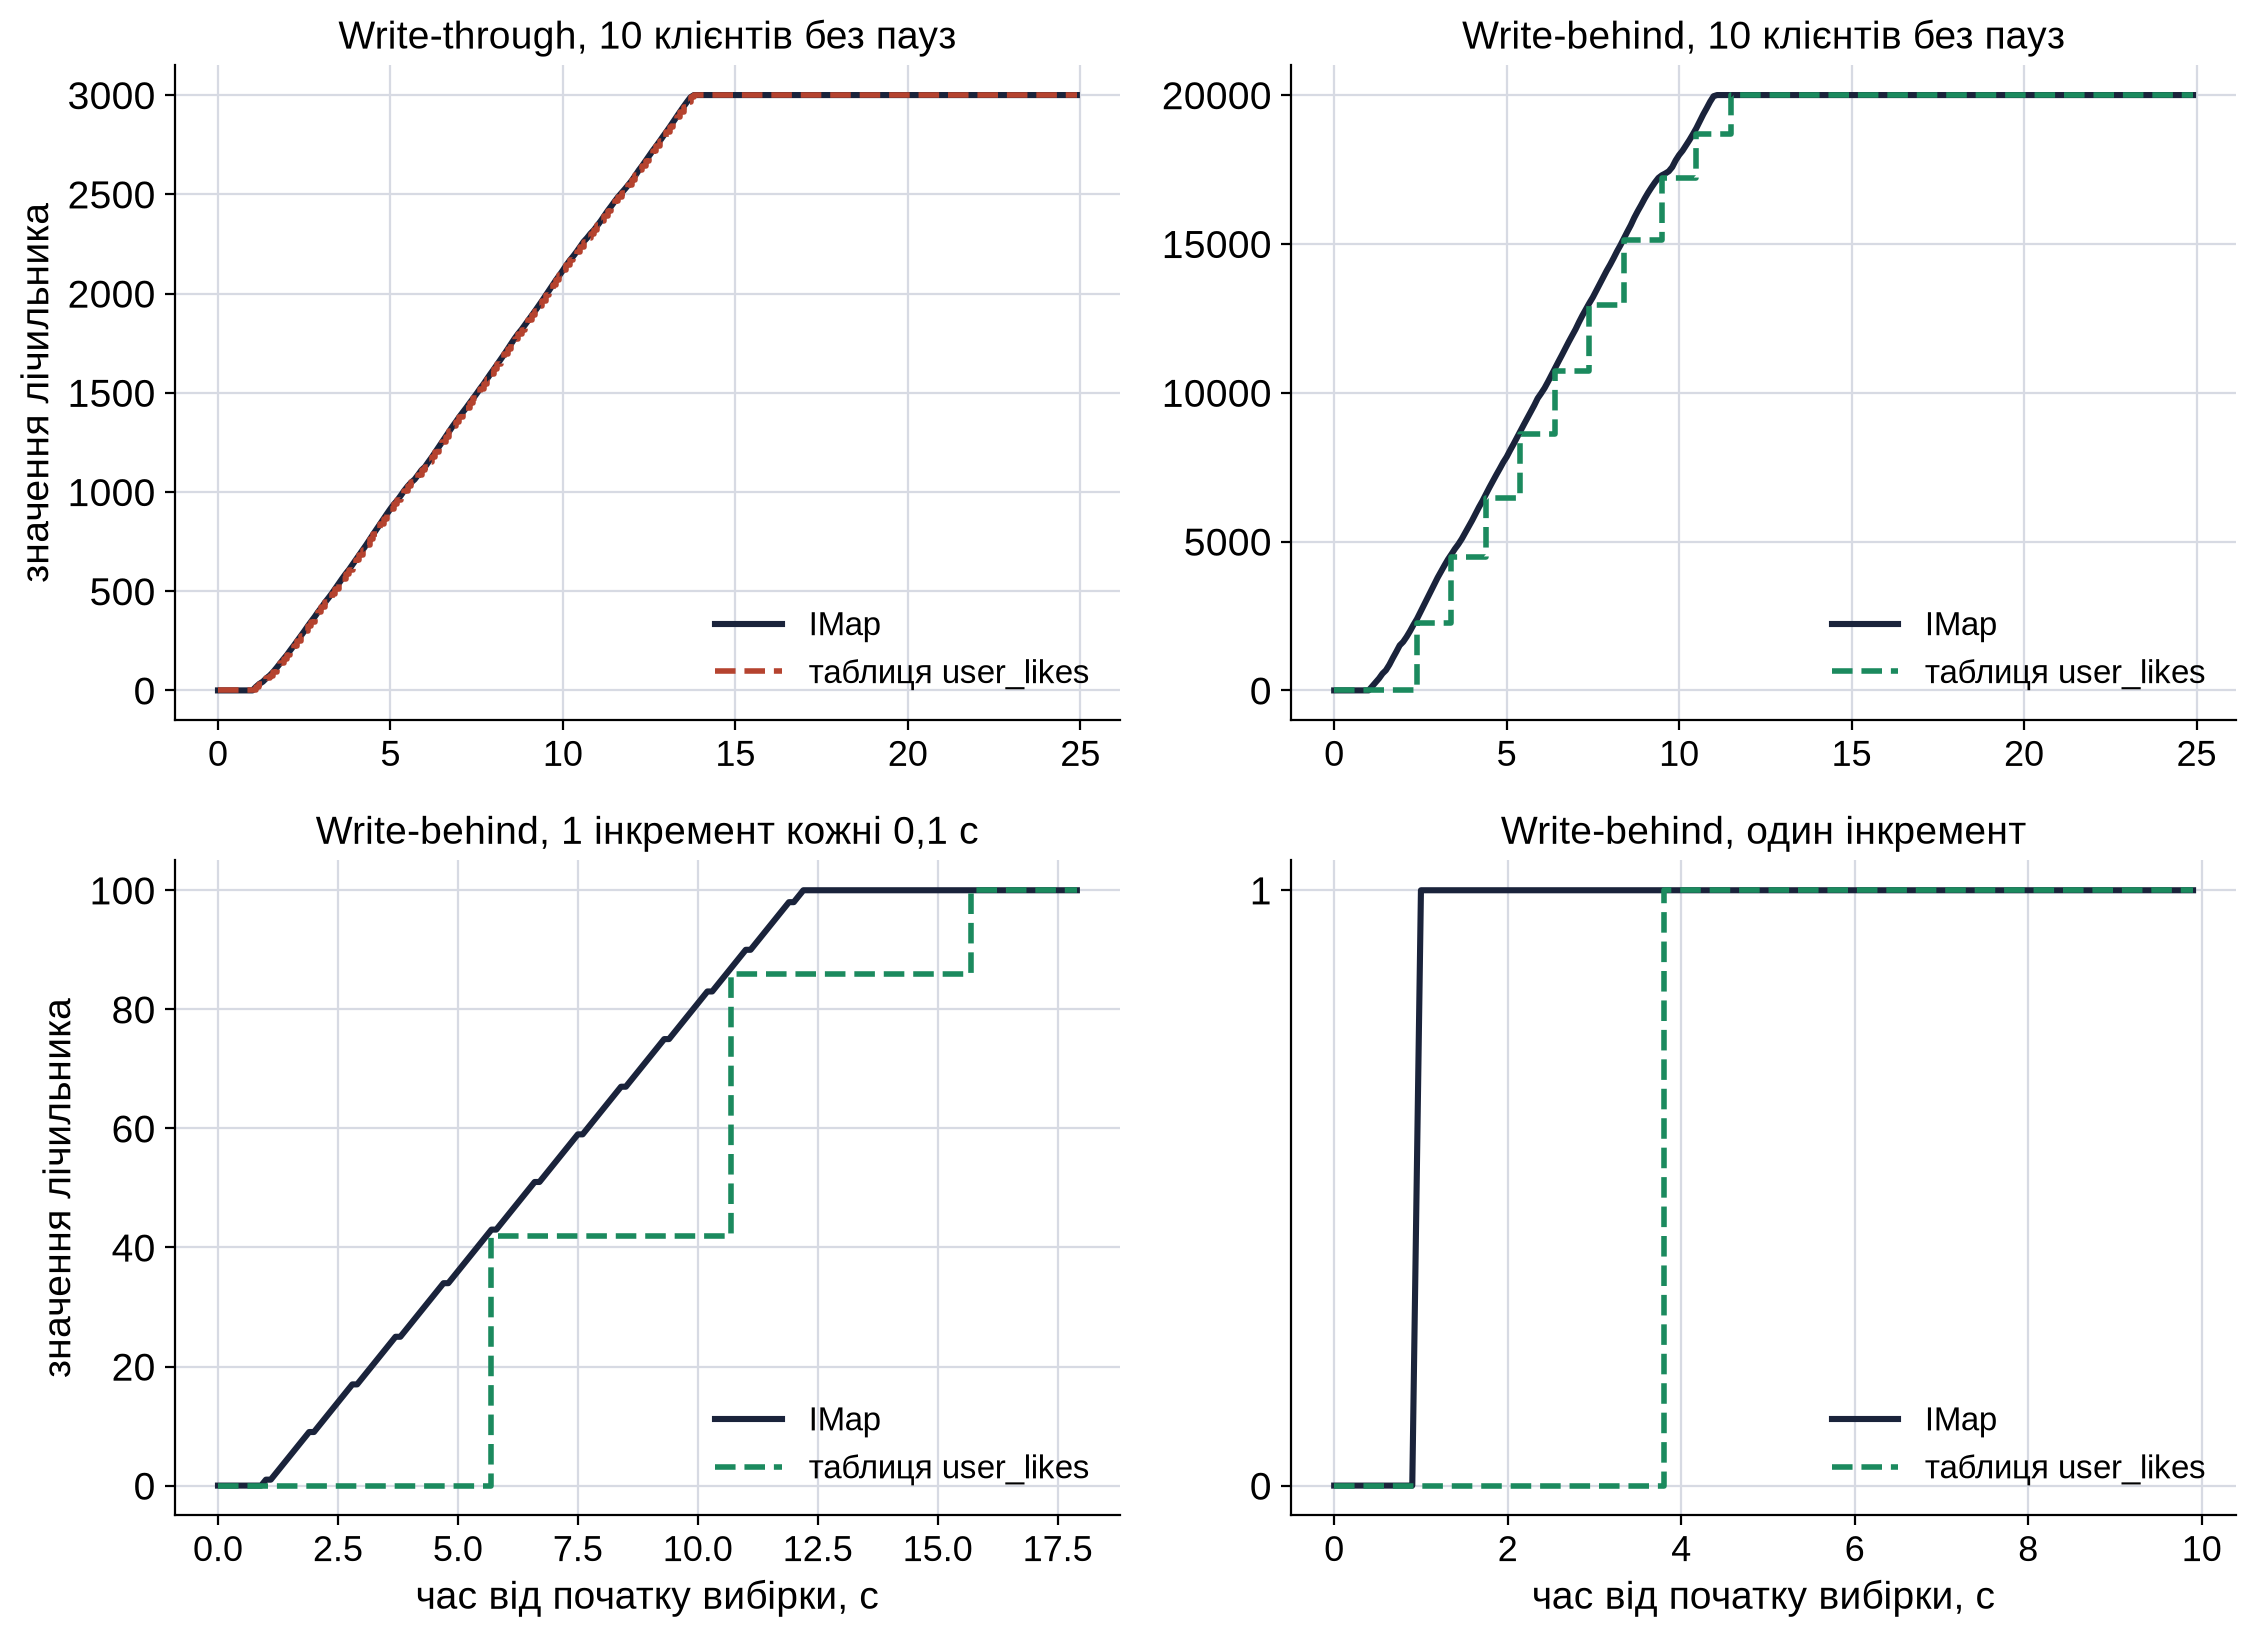

збережено: Labs/06-caching/assets/lag.png


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(11.5, 8.4))
panels = (("likes_write_through", "Write-through, 10 клієнтів без пауз", COLOR["Hazelcast Write-through"]),
          ("likes_write_behind", "Write-behind, 10 клієнтів без пауз", COLOR["Hazelcast Write-behind"]),
          ("trickle", "Write-behind, 1 інкремент кожні 0,1 с", COLOR["Hazelcast Write-behind"]),
          ("single", "Write-behind, один інкремент", COLOR["Hazelcast Write-behind"]))
for ax, (name, title, color) in zip(axes.flat, panels):
    d = lag[name]
    ax.plot(d["seconds"], d["imap"], color=INK, linewidth=2.2, label="IMap")
    ax.step(d["seconds"], d["db"], where="post", color=color, linewidth=2, linestyle="--",
            label="таблиця user_likes")
    ax.set_title(title)
    ax.grid(color=GRID, linewidth=0.8)
    ax.legend(loc="lower right", frameon=False)
for ax in axes[1]:
    ax.set_xlabel("час від початку вибірки, с")
for ax in axes[:, 0]:
    ax.set_ylabel("значення лічильника")
axes[1, 1].set_yticks([0, 1])
fig.tight_layout()
save(fig, "lag.png")

## 7. Навантаження машини під час прогонів

Попередній запуск (17.11 увечері) зупинено, бо середнє навантаження
машини сягало 38 на 16 потоках через сторонні процеси; ці числа не
використано. Під час прогонів звіту скрипт кожні 10 с записував
`/proc/loadavg`:

In [13]:
load = pd.read_csv(LOGS / "taskadv1-loadavg.txt", sep=" ", names=["час (UTC)", "1 хв", "5 хв", "15 хв"])
print(f"вибірок {len(load)}, {load['час (UTC)'].iloc[0]}...{load['час (UTC)'].iloc[-1]} UTC; "
      f"навантаження за 1 хв: медіана {uk(load['1 хв'].median(), 1)}, макс {uk(load['1 хв'].max(), 1)}")

вибірок 275, 02:03:27...08:44:34 UTC; навантаження за 1 хв: медіана 7,2, макс 32,3


## 8. Жива перевірка

Якщо PostgreSQL і кластер запущено (`scripts/pg.sh start`,
`scripts/hz.sh start`), сервер по черзі працює з кожним сховищем, `loadgen`
робить 10 × 100 інкрементів одного користувача, а `cache-check`
порівнює мапу з таблицею. Числа звіту беруться не звідси, а з CSV.

In [14]:
def port_open(port: int) -> bool:
    try:
        with socket.create_connection(("127.0.0.1", port), timeout=1):
            return True
    except OSError:
        return False


BIN = ROOT / ".build" / "release"
tools = [BIN / n for n in ("counter-server", "loadgen", "cache-check")]
if not RUN_LIVE:
    print("RUN_LIVE = False: пропускаю")
elif not all(t.is_file() for t in tools) or not (port_open(21410) and port_open(5701)):
    print("PostgreSQL або кластер не запущено, або програми не зібрано: пропускаю "
          "(scripts/pg.sh start; scripts/hz.sh start; swift build -c release)")
else:
    live = []
    for store, args in (("postgres-users", []),
                        ("hazelcast-write-through", ["--store", "hazelcast-cache", "--hz-map", "likes_write_through"]),
                        ("hazelcast-write-behind", ["--store", "hazelcast-cache", "--hz-map", "likes_write_behind"])):
        cmd = [str(tools[0]), "--port", "21499"] + (args or ["--store", "postgres-users"])
        server = subprocess.Popen(cmd, stderr=subprocess.DEVNULL)
        try:
            for _ in range(100):
                if port_open(21499):
                    break
                time.sleep(0.1)
            out = subprocess.run([str(tools[1]), "--header", "--clients", "10", "--requests", "100", "--user-id", "1",
                                  "--url", "http://127.0.0.1:21499", "--store-label", store],
                                 capture_output=True, text=True, timeout=600, check=True).stdout
        finally:
            server.terminate()
            server.wait()
        header, row = out.strip().splitlines()[-2:]
        result = dict(zip(header.split(","), row.split(",")))
        if store != "postgres-users":
            chk = subprocess.run([str(tools[2]), "--map", args[-1], "--users", "1", "--wait", "15"],
                                 capture_output=True, text=True, timeout=60)
            result["мапа = таблиця"] = chk.returncode == 0
        live.append(result)
    live = pd.DataFrame(live)
    display(live)
    assert (live["final_value"] == live["expected"]).all()

,store,clients,requests_per_client,total_requests,seconds,rps,final_value,expected,correct,мапа = таблиця
0,postgres-users,10,100,1000,3.2185,310.7,1000,1000,true,NaN
1,hazelcast-write-through,10,100,1000,5.4468,183.6,1000,1000,true,True
2,hazelcast-write-behind,10,100,1000,0.5957,1678.7,1000,1000,true,True


## 9. Висновки

Числа нижче обчислено вище в цьому ноутбуці.

In [15]:
for name, r in shared.iterrows():
    conflicts = "" if pd.isna(r["конфліктів на інкремент"]) else f", конфліктів на інкремент {uk(r['конфліктів на інкремент'], 2)}"
    print(f"{name}: {uk(r['час, с (медіана)'], 1)} с, {uk(r['інкр./с (медіана)'], 1)} інкр./с, "
          f"рядків записано {r['рядків записано (медіана)']}{conflicts}")
print(f"10 користувачів: PostgreSQL {uk(pg_d, 1)}, write-through {uk(wt_d, 1)}, write-behind {uk(wb_d, 1)} інкр./с")
print("усі прогони дали 100 000; після кожного мапа = таблиця, і після evictAll мапа прочитала те саме з таблиці")
print(f"write-behind: таблиця оновлювалась кожні {uk(lag_table.iloc[1, 1], 1)} с під навантаженням, "
      f"кожні {uk(lag_table.iloc[2, 1], 1)} с при рідких змінах; одна зміна дійшла за {uk(single_delay, 1)} с")

PostgreSQL: 149,9 с, 667,0 інкр./с, рядків записано 100001
Hazelcast Write-through: 323,2 с, 309,4 інкр./с, рядків записано 100001, конфліктів на інкремент 4,60
Hazelcast Write-behind: 39,4 с, 2 540,2 інкр./с, рядків записано 39, конфліктів на інкремент 4,48
10 користувачів: PostgreSQL 3 464,7, write-through 1 149,5, write-behind 7 323,8 інкр./с
усі прогони дали 100 000; після кожного мапа = таблиця, і після evictAll мапа прочитала те саме з таблиці
write-behind: таблиця оновлювалась кожні 1,0 с під навантаженням, кожні 5,0 с при рідких змінах; одна зміна дійшла за 2,8 с
